# LogiPredict — treinamento temporal e revisão de alertas

**Objetivo:** antecipar o maior número de atrasos reais com o menor número de falsos alertas possível. Não há um único máximo para os dois objetivos: aumentar a sensibilidade costuma aumentar os alertas. Por isso comparamos métodos sob critérios escritos antes da avaliação final.

Este notebook executa uma pesquisa reproduzível, explica as escolhas e exporta um candidato para homologação. **Não substitui automaticamente o modelo da aplicação.** Os notebooks anteriores e os arquivos existentes do projeto permanecem preservados.

O resultado será o melhor **entre as configurações avaliadas, pelo critério declarado**, não uma prova de que nenhuma técnica futura poderia melhorar. O conjunto histórico final já apareceu nas pesquisas anteriores: esta é uma comparação retrospectiva, não uma confirmação independente.

## 1. Ambiente e organização

Pandas e NumPy organizam os dados. Scikit-learn fornece transformações, Random Forest, regressão logística e métricas. CatBoost, LightGBM e XGBoost oferecem alternativas de árvores. XGBoost AFT estima o tempo até a entrega. Joblib salva os mesmos objetos avaliados. FastAPI e Pydantic permitem verificar o contrato do serviço final.

Instale o pacote e o ambiente de pesquisa a partir da raiz do repositório:

```powershell
.\.venv\Scripts\python.exe -m pip install -e "ML/final_risk_training[research]"
```

Execute o comando na **raiz do repositório**. Selecione o Python dessa `.venv` como kernel do notebook. O diretório `logipredict_final` acompanha o notebook e contém as funções comentadas reutilizadas na API.

In [1]:
# Limitamos as threads para não ocupar todo o computador durante a busca.
import os
for variable in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:
    os.environ[variable]='4'
from pathlib import Path
import json,hashlib,joblib
import numpy as np
import pandas as pd
from IPython.display import display,Markdown,Image
import logipredict_final
from logipredict_final.data import load_orders,shipment_row
from logipredict_final.features import feature_frame,enrich,FEATURES
from logipredict_final.experiment import *
from logipredict_final.evaluation import evaluate_selected,compare_shipped_model,export_selected
from logipredict_final.checks import verify
from logipredict_final.reporting import diagnostics,write_report
from logipredict_final.refinements import run_refinements,run_maturity
ROOT=Path(logipredict_final.__file__).resolve().parents[1]
WORK=ROOT/'artifacts'
WORK.mkdir(exist_ok=True)
RETRAIN=False  # True refaz a busca inteira; False reaproveita somente cache compatível.
print('Pacote:',ROOT)
print('Critério principal: alvo de recall de 90% na calibração, avaliado no mês seguinte.')

Pacote: D:\Documentos\FACULDADE\5 semestre\LogiPredictAI\ML\final_risk_training
Critério principal: alvo de recall de 90% na calibração, avaliado no mês seguinte.


## 2. Dados reais usados

Lemos seis tabelas Olist: **pedidos, itens, clientes, produtos, vendedores e geolocalização**. Todos os itens de um pedido entram na soma de peso, volume, preço e frete. Quando há mais de um vendedor, a distância usada é a maior distância até o cliente e a UF de origem é a do primeiro item, convenção que precisa ser mantida ao montar a entrada real.

Os CEPs de cinco dígitos localizam coordenadas medianas, após remoção de duplicatas e coordenadas fora dos limites geográficos usados para o Brasil. A distância é em linha reta: não representa uma rota rodoviária. CEP é um identificador, não uma grandeza numérica em que CEP maior signifique maior distância.

Mantemos pedidos entregues com datas consistentes. Não inventamos pedidos, desfechos, vendedores, feriados ou medidas ausentes. As ausências numéricas são preenchidas com a mediana aprendida **somente no ajuste de cada modelo**, com indicador de ausência. O manifesto registra linhas e SHA-256 de cada arquivo. Os dados podem vir de `OLIST_DATASET_PATH`, da pasta do projeto ou dos objetos Git da main no commit fixado no código, sem trocar a branch.

Definimos **atraso como classe positiva (1)**. Nesta base filtrada, os atrasos são a minoria: aproximadamente 6,8%; os pedidos pontuais representam 93,2%. Por isso acertar quase todos os pontuais, sozinho, não demonstra que estamos encontrando atrasos.

In [2]:
# A leitura real também valida a origem do cache; trocar o CSV exige um novo treino.
data,manifest=load_orders()
display(pd.Series(manifest['quality'],name='Quantidade'))
display(pd.DataFrame(manifest['manifest']))
TEST_START=data.dispatched_at.iloc[int(len(data)*.8)]
test=data.loc[data.dispatched_at.ge(TEST_START)]
print('Início do período final:',TEST_START)
display(pd.DataFrame({
    'Grupo':['Período final inteiro','Prazo já vencido no despacho','Ainda era possível antecipar'],
    'Pedidos':[len(test),int(test.already_overdue.sum()),int((~test.already_overdue).sum())],
    'Atrasos':[int(test.is_late.sum()),int(test.already_overdue.sum()),int(test.loc[~test.already_overdue,'is_late'].sum())]
}))

raw_orders                       99441.000000
eligible_orders                  96281.000000
late_orders                       6531.000000
late_rate                            0.067833
sellers                           3095.000000
orders_with_missing_measure        503.000000
multiple_seller_orders            1252.000000
geo_rows_filtered_after_dedup       25.000000
Name: Quantidade, dtype: float64

,table,rows,sha256
0,orders,99441,8df58ef3d2d7e9944010f7beecd9b75367f5588ec6e3c9...
1,order_items,112650,0bc4d068c4fe38cbb01bd90e8746e3c613fe7b4baef75f...
2,customers,99441,983a422239e1712ded753b3bf9ecf47dc73f144d306029...
3,products,32951,3e6569628a17fbc75fd206ee357b59e20364b9afa90f5b...
4,sellers,3095,1f643d2b950373b85735e7794b20986f528d7a000432e7...
5,geolocation,1000163,b514f6fc991b9566aeba02aa5d67e2c3630f034b60a0e0...


Início do período final: 2018-05-29 12:04:00


,Grupo,Pedidos,Atrasos
0,Período final inteiro,19258,704
1,Prazo já vencido no despacho,132,132
2,Ainda era possível antecipar,19126,572


## 3. O que o modelo pode saber

A previsão acontece **no despacho**, não na compra. O alvo é `data real da entrega > data prometida`, comparando dias de calendário. A entrega real e o status final servem para medir acertos; não entram como atributos.

O serviço Python da main transforma o JSON em 13 atributos. Preservamos esse contrato: peso, volume, distância, itens, vendedores, preço, frete, tempo entre compra e despacho, dias restantes, mês da compra, dia da semana do despacho e UFs.

A partir desses dados acrescentamos: regiões brasileiras, par de UFs, mesma UF ou interestadual, peso/preço/frete por item, densidade, frete em relação ao preço, distância em relação ao prazo, proporção do prazo consumida no despacho, logaritmos de medidas, fins de semana e meses de pico. São cálculos sobre dados existentes, não novos fatos.

**IDs de vendedores, CEPs, categoria e histórico individual existem nos CSVs, mas não chegam ao modelo no contrato atual da main.** As pesquisas anteriores exploraram parte deles. Este candidato prioriza funcionamento real no serviço existente; não promete explorar todas as entradas possíveis. Feriados específicos precisam de data completa/localidade; essas informações também são descartadas no frame atual. Usar esses atributos na próxima versão exige ampliar explicitamente o contrato e manter um histórico causal disponível na inferência. Não preenchemos identidades ou taxas históricas fictícias para esconder essa diferença.

In [3]:
# A mesma função monta a entrada no treinamento e no serviço candidato.
x=feature_frame(data.iloc[:3])
display(x)
display(pd.Series(enrich(x).columns,name='Atributos após cruzamentos'))
print('Contrato original:',len(FEATURES),'atributos; após cruzamentos:',enrich(x).shape[1])

,distance_km,total_weight_g,total_volume_cm3,items_count,sellers_count,price,freight_value,dispatch_lead_days,remaining_days,purchase_month,dispatch_weekday,seller_state,customer_state
0,194.576270,9000.0,2640.0,1.0,1.0,29.99,10.96,4.501736,46,10,5,SP,SP
1,1043.478635,3000.0,29250.0,2.0,1.0,47.80,53.64,4.024340,59,10,5,SP,MT
2,988.066003,1200.0,12500.0,1.0,1.0,93.90,17.61,4.023229,53,10,5,PR,RJ


0              distance_km
1           total_weight_g
2         total_volume_cm3
3              items_count
4            sellers_count
5                    price
6            freight_value
7       dispatch_lead_days
8           remaining_days
9           purchase_month
10        dispatch_weekday
11            seller_state
12          customer_state
13             route_state
14           seller_region
15         customer_region
16              interstate
17         log_distance_km
18      log_total_weight_g
19    log_total_volume_cm3
20               log_price
21       log_freight_value
22           freight_ratio
23         weight_per_item
24          price_per_item
25        freight_per_item
26                 density
27        distance_per_day
28       dispatch_fraction
29        promised_weekday
30        dispatch_weekend
31        promised_weekend
32              peak_month
Name: Atributos após cruzamentos, dtype: object

Contrato original: 13 atributos; após cruzamentos: 33


## 4. Como evitamos aprender o futuro

Não embaralhamos pedidos entre treino e teste. Avaliamos quatro meses futuros: dezembro/2017 e fevereiro, março e abril/2018. Para cada início de mês E:

1. Somente despachos anteriores a E podem participar do treino.
2. O bloco entre E−35 e E−14 dias fica reservado para calibração e nunca entra no ajuste do detector.
3. Nos classificadores, só usamos rótulos já conhecidos em E: entrega já ocorrida, ou fim do dia prometido já ultrapassado sem entrega. Na sobrevivência, entregas ainda desconhecidas entram como observações censuradas, sem ler sua data futura.
4. A mediana e o vocabulário das categorias são aprendidos novamente em cada ajuste.
5. A decisão é avaliada nos despachos do mês seguinte. Para selecionar modelos, os desfechos desses meses precisam estar disponíveis antes do início do período final.

O detector pode usar pedidos anteriores a E que sejam mais recentes que o bloco de calibração. Portanto o bloco é uma amostra passada separada, **não** uma simulação em que todo treino é anterior à calibração. A avaliação futura começa sempre depois de ambos.

Pedidos cujo prazo já venceu no despacho são sinalizados por regra e ficam separados do recall de antecipação. Reconhecer um atraso já ocorrido não é a mesma coisa que prevê-lo.

In [4]:
# Inspecionamos as janelas e os rótulos disponíveis, sem ler resultados do teste final.
windows=[]
for start in DEV_STARTS:
    train,cal,cal_all,future=split_at(data,start,pd.Timestamp(start)+pd.DateOffset(months=1),TEST_START)
    windows.append(dict(inicio=start,treino_rotulo_conhecido=int((train.label_known_at<pd.Timestamp(start)).sum()),
        treino_ainda_censurado=int((train.delivered_at>=pd.Timestamp(start)).sum()),
        calibracao=len(cal),calibracao_sem_rotulo_excluida=len(cal_all)-len(cal),validacao_futura=len(future)))
display(pd.DataFrame(windows))

,inicio,treino_rotulo_conhecido,treino_ainda_censurado,calibracao,calibracao_sem_rotulo_excluida,validacao_futura
0,2017-12-01,31164,2933,2780,92,6000
1,2018-02-01,44014,1899,3691,317,6484
2,2018-03-01,49686,2497,3907,341,7026
3,2018-04-01,56432,2005,4487,593,6857


## 5. Tecnologias e busca comparativa

Comparamos 55 configurações, cada uma nos quatro meses: **7 classificadores iniciais, 18 modelos de sobrevivência, 8 cascatas, 4 regressões de duração, 3 Random Forest com atributos derivados, 9 combinações entre modelos e 6 alternativas de maturação temporal**. São 220 comparações temporais. A busca é finita e reprodutível, com semente 42, quatro threads e configurações explícitas em `experiment.py` e `refinements.py`.

A pesquisa teve duas rodadas: a primeira comparou classificadores, AFT e cascatas; a segunda acrescentou regressão de duração e combinações, após observar que a primeira não resolvia satisfatoriamente o custo de alarmes. O mesmo critério e os mesmos quatro meses de desenvolvimento foram mantidos. A segunda rodada também deve ser considerada exploratória, pois o período histórico final já havia sido consultado.

- **Random Forest:** referência com os parâmetros da aplicação, reajustada sob o mesmo protocolo temporal dos candidatos.
- **CatBoost, LightGBM, XGBoost e HistGradientBoosting:** alternativas de árvores, algumas com maior peso para atrasos. Aqui usamos codificação One-Hot comum, inclusive no CatBoost, para manter a transformação compartilhada e auditável.
- **Regressão logística:** verificador simples com `StandardScaler` nos números; a escala evita que unidades muito grandes dominem esse modelo. Árvores não precisam desse escalonamento.
- **AFT:** aprende o tempo até entregar, em vez de somente sim/não. Testamos distribuições normal, logística e extrema, escalas 0,5/1/1,5 e profundidades 3/5. Entregas concluídas entram como duração exata; entregas futuras entram como intervalo `[tempo já observado, infinito]`. Somamos um dia às durações de calendário para evitar duração zero.
- **Calibração sigmoide:** transforma o score em uma estimativa de probabilidade no bloco passado reservado. Isso não garante calibração em uma operação futura.
- **Regressão de duração:** CatBoost estima dias de entrega com erro quadrático ou quantis 50/80/90; a folga entre duração prevista e prazo ordena o risco. Aqui só entram entregas efetivamente concluídas antes do ajuste, inclusive quando o rótulo binário de atraso já era conhecido antes da entrega.
- **Combinação de modelos:** combina os logits dos scores calibrados de RF/AFT, CatBoost/AFT ou RF/CatBoost, com pesos 25/75, 50/50 e 75/25. A ideia é aproveitar erros diferentes; os pesos são comparados apenas na validação.
- **Maturação temporal:** comparamos RF e CatBoost excluindo despachos dos últimos 35 ou 60 dias do ajuste, mantendo a calibração original; na terceira alternativa usamos calibração entre E−60 e E−35 e ajuste em despachos anteriores a E−60. Todos os rótulos usados precisam estar conhecidos em E. Isso testa o viés de incluir, entre os pedidos muito recentes, somente os que já tiveram uma resposta rápida. É uma alternativa de validação, não uma forma de fabricar rótulos para pedidos ainda abertos.

Não fazemos SMOTE nem duplicamos atrasos artificialmente. Não usamos overfitting como estratégia: decorar o treino melhora os números do passado e prejudica pedidos novos.

## 6. Sua ideia: detector e revisor de falsos alertas

O primeiro detector busca aproximadamente **97,5% dos atrasos na calibração**. O segundo recebe somente alarmes históricos e aprende a distinguir atrasos reais de entregas pontuais que enganaram o detector.

Para montar esse material geramos previsões de agosto/2017 a abril/2018, treinando cada detector somente com o passado de cada mês. O revisor nunca aprende com o resultado do próprio detector nos pedidos usados para ajustar esse detector. Antes de cada ajuste do revisor, ainda exigimos que o rótulo estivesse conhecido naquela data e excluímos seu bloco de calibração.

O revisor recebe os atributos calculáveis do pedido, o score do detector e sua posição em relação aos negativos da calibração histórica. Negativos difíceis recebem mais peso, e atrasos reais também recebem peso alto para evitar descartá-los em excesso. Testamos regressão logística e LightGBM como revisores, com dois esquemas de peso cada, sobre dois detectores.

A decisão final exige passar pelos dois cortes. Um revisor também pode descartar atrasos verdadeiros; por isso mostramos **quantos falsos alarmes removeu e quantos atrasos perdeu**. A segunda etapa só merece ser escolhida se a validação mostrar vantagem pelo critério comum.

In [5]:
# O cache só é aceito se dados e código de treinamento coincidirem.
sources=['data.py','features.py','runtime.py','experiment.py','refinements.py','evaluation.py']
signature=hashlib.sha256(b''.join((ROOT/'logipredict_final'/p).read_bytes() for p in sources)).hexdigest()
cache_ok=False
if (WORK/'run_signature.json').exists() and (WORK/'selection.joblib').exists():
    old=json.loads((WORK/'run_signature.json').read_text(encoding='utf-8'))
    old_manifest=json.loads((WORK/'data_manifest.json').read_text(encoding='utf-8'))
    cache_ok=old['source_sha256']==signature and old_manifest==manifest
if RETRAIN or not cache_ok:
    joblib.dump(data,WORK/'orders_clean.joblib')
    (WORK/'data_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
    development,summary,oof=run_development(data,WORK)
    development,summary,oof=run_refinements(data,WORK)
    development,summary,oof=run_maturity(data,WORK)
    # Reexecutar o desenvolvimento também reexecuta a avaliação/exportação abaixo.
    cache_ok=False
else:
    saved=joblib.load(WORK/'selection.joblib')
    development,summary,oof=saved['records'],saved['summary'],saved['oof']
    print('Resultados calculados anteriormente com estes mesmos dados e fontes; cache validado.')
display(summary.reset_index().head(12))
print('Comparações temporais:',len(development),'| Configurações:',len(summary))

Resultados calculados anteriormente com estes mesmos dados e fontes; cache validado.


,name,family,objective,variation,recall,FPR,AP,selection_score
0,blend_cb150_aft_extreme_0.5_3_0.5,blend,0.580804,0.135521,0.919896,0.577332,0.350323,0.614685
1,blend_rf_main_aft_extreme_0.5_3_0.5,blend,0.585125,0.125310,0.913925,0.569450,0.359828,0.616453
2,blend_rf_main_aft_extreme_0.5_3_0.25,blend,0.583916,0.138826,0.927962,0.583916,0.363760,0.618623
3,blend_cb150_aft_extreme_0.5_3_0.25,blend,0.598280,0.135598,0.925825,0.591335,0.356938,0.632179
4,aft_extreme_0.5_3,aft,0.612280,0.136107,0.928182,0.601863,0.359771,0.646306
5,blend_cb150_aft_extreme_0.5_3_0.75,blend,0.617276,0.154824,0.900561,0.559398,0.342023,0.655982
6,aft_normal_0.5_5,aft,0.626403,0.121790,0.921850,0.602097,0.368936,0.656850
7,blend_rf_main_aft_extreme_0.5_3_0.75,blend,0.634865,0.098225,0.896597,0.565750,0.350258,0.659421
8,aft_normal_0.5_3,aft,0.633665,0.159065,0.933779,0.630193,0.373651,0.673431
9,aft_extreme_0.5_5,aft,0.658989,0.115346,0.924934,0.624267,0.355374,0.687825


Comparações temporais: 220 | Configurações: 55


## 7. Critério escolhido antes da avaliação final

O objetivo principal é buscar recall de **90% dos atrasos ainda não vencidos**. O corte de cada modelo é definido para atingir esse alvo na calibração passada. Depois medimos recall e taxa de falsos alertas no mês seguinte.

A nota por mês é `FPR + 5 × max(0, 0,90 − recall)`. FPR é a fração dos pedidos pontuais que receberam alarme. A nota final é a média mensal mais 0,25 vezes seu desvio padrão. Quanto menor, melhor. Esse peso dá prioridade explícita ao recall sem ignorar o custo dos alertas nem a instabilidade entre meses.

Também apresentamos perfis com alvos de 80% e 95%, definidos no mesmo bloco passado. **Alvo na calibração não é promessa de recall no teste.** Não ajustamos o corte olhando os erros finais.

In [6]:
# Congelamos a escolha pela validação antes de abrir as métricas finais.
if RETRAIN or not cache_ok or not (WORK/'evaluation.joblib').exists():
    result=evaluate_selected(data,WORK)
else:
    result=joblib.load(WORK/'evaluation.joblib')
assert result['frozen']['primary']==summary.reset_index().iloc[0]['name']
display(Markdown('**Candidato escolhido na validação:** `'+result['frozen']['primary']+'`.'))
display(result['table'][['name','target','TP','TP_total','FP','FN','recall','recall_total','precision','ROC_AUC','AP','brier']])

**Candidato escolhido na validação:** `blend_cb150_aft_extreme_0.5_3_0.5`.

,name,target,TP,TP_total,FP,FN,recall,recall_total,precision,ROC_AUC,AP,brier
0,blend_cb150_aft_extreme_0.5_3_0.5,0.80,482,614,6929,90,0.842657,0.872159,0.065038,0.850362,0.428081,0.021782
1,blend_cb150_aft_extreme_0.5_3_0.5,0.90,527,659,10125,45,0.921329,0.936080,0.049474,0.850362,0.428081,0.021782
2,blend_cb150_aft_extreme_0.5_3_0.5,0.95,552,684,12739,20,0.965035,0.971591,0.041532,0.850362,0.428081,0.021782
3,rf_main,0.80,498,630,7981,74,0.870629,0.894886,0.058733,0.815517,0.221076,0.026108
4,rf_main,0.90,540,672,11090,32,0.944056,0.954545,0.046432,0.815517,0.221076,0.026108
5,rf_main,0.95,559,691,14168,13,0.977273,0.981534,0.037957,0.815517,0.221076,0.026108
6,cascade_cb150_lr_hard3,0.80,426,558,6038,146,0.744755,0.792614,0.065903,0.796154,0.284274,0.024837
7,cascade_cb150_lr_hard3,0.90,499,631,9728,73,0.872378,0.896307,0.048792,0.808804,0.316265,0.024103
8,cascade_cb150_lr_hard3,0.95,534,666,11345,38,0.933566,0.946023,0.044953,0.824240,0.339656,0.023608
9,aft_extreme_0.5_3,0.80,484,616,7181,88,0.846154,0.875000,0.063144,0.854019,0.431030,0.022607


## 8. Como ler os resultados

**TP** é atraso antecipado corretamente. **TP_total** soma também os 132 pedidos que já estavam com prazo vencido no despacho. **FP** é um alarme sobre pedido que chegou no prazo. **FN** é atraso que passou sem alarme. Recall mede a fração dos atrasos encontrados; precisão mede quantos alarmes eram atrasos reais.

ROC-AUC e AP comparam a ordenação dos pedidos, mas não substituem a contagem no corte usado. Brier mede erro da estimativa probabilística (menor é melhor), mas também depende da frequência de atrasos. As métricas desta seção usam somente os pedidos que ainda podiam ser antecipados, exceto as colunas explicitamente marcadas como total.

In [7]:
# Comparamos também os pesos efetivamente versionados na main, sem substituí-los.
main=compare_shipped_model(data,WORK)
display(pd.DataFrame([{'modelo':'Modelo original da main, corte original',**main['original_full_test']}]))
display(result['details'])
display(Markdown('Na tabela da cascata, `removed_false_alerts` é o ganho da revisão e `lost_true_late` é o preço pago em atrasos descartados, sempre comparando com seu detector de alta sensibilidade.'))

,modelo,TP,FP,FN,TN,recall,precision,FPR,ROC_AUC,AP
0,"Modelo original da main, corte original",564,4364,140,14190,0.801136,0.114448,0.235205,0.866973,0.370448


,name,target,detector_TP,detector_FP,removed_false_alerts,lost_true_late
0,cascade_cb150_lr_hard3,0.80,551,12672,6634,125
1,cascade_cb150_lr_hard3,0.90,551,12672,2944,52
2,cascade_cb150_lr_hard3,0.95,551,12672,1327,17


Na tabela da cascata, `removed_false_alerts` é o ganho da revisão e `lost_true_late` é o preço pago em atrasos descartados, sempre comparando com seu detector de alta sensibilidade.

## 9. O ganho é só por abaixar o corte?

Um modelo antigo também encontra mais atrasos se seu corte for reduzido. Para investigar melhoria de ordenação, calculamos abaixo quantos falsos alertas o modelo da main precisaria gerar para alcançar o mesmo recall de antecipação do candidato.

**Este diagnóstico usa o teste para localizar um corte equivalente. É um oráculo retrospectivo e não pode ser exportado como regra de produção.** Serve para não confundir aumento de sensibilidade com um algoritmo realmente melhor.

,target,matched_recall,TP,FP,FN,TN,recall,precision,FPR,ROC_AUC,AP
0,0.80,0.842657,482,5933,90,12621,0.842657,0.075136,0.319769,0.840374,0.242858
1,0.90,0.921329,527,9513,45,9041,0.921329,0.052490,0.512720,0.840374,0.242858
2,0.95,0.965035,552,11931,20,6623,0.965035,0.044220,0.643042,0.840374,0.242858


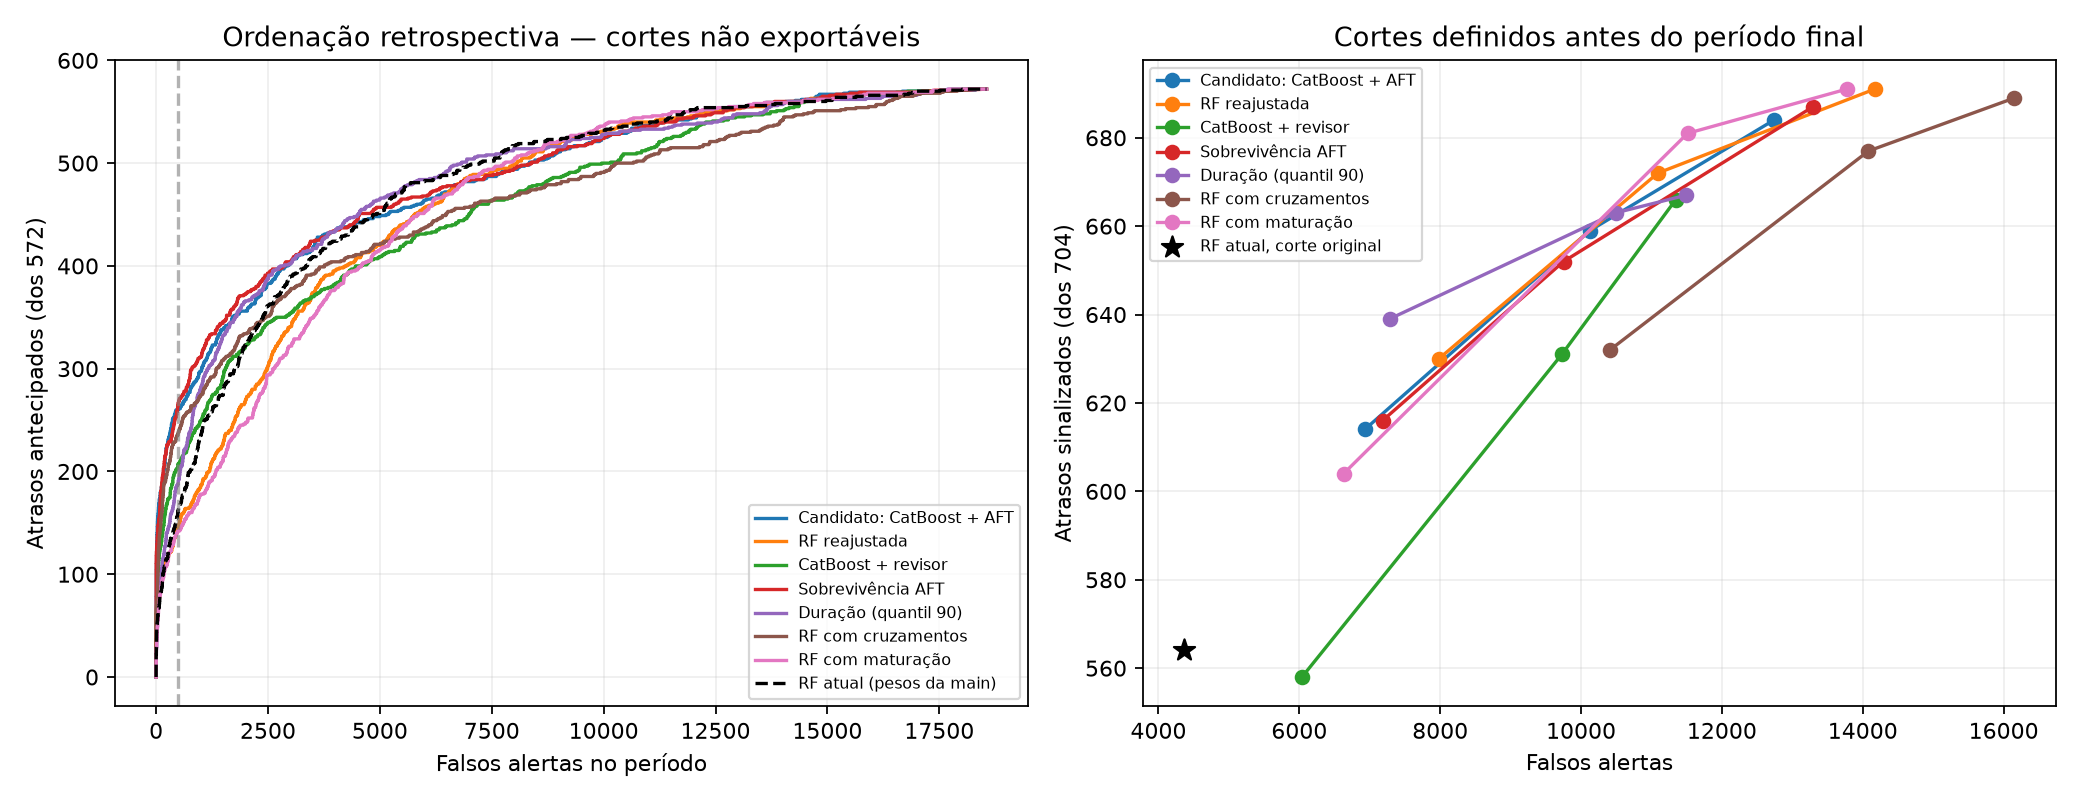

Diagnóstico de orçamento de 500 falsos alertas: {'FP': 497, 'TP_proactive': 261, 'TP_total': 393, 'warning': 'Oracle retrospectivo: usa os rótulos do teste; não é um corte de produção nem limite universal.'}
Diferenças pareadas e incerteza por semanas: {'delta_TP_proactive': 93, 'delta_FP': 5761, 'weekly_bootstrap_95pct_TP': [52.0, 147.0], 'weekly_bootstrap_95pct_FP': [3640.775, 7982.125], 'note': 'Comparação pareada no mesmo período; não corrige seleção histórica nem prova desempenho futuro.'}


In [8]:
display(pd.DataFrame(main['oracle_matching_recall_not_deployable']))
regions,budget,uncertainty=diagnostics(WORK)
display(Image(filename=str(WORK/'tradeoff.png')))
print('Diagnóstico de orçamento de 500 falsos alertas:',budget)
print('Diferenças pareadas e incerteza por semanas:',uncertainty)

## 10. Regiões e mudança ao longo do tempo

Essas tabelas mostram onde o modelo erra mais; não ajustam o modelo usando o teste. Podem orientar os filtros futuros do mapa por UF, região e data. Cada pedido continua sendo uma observação: separar mapas não significa criar dados novos.

Uma região com poucos atrasos tem recall instável. As taxas observadas em 2018 não devem ser apresentadas como previsão garantida para 2026. O relatório por mês também ajuda a identificar mudança do padrão de entregas.

In [9]:
display(regions)
display(pd.read_csv(WORK/'monthly_report.csv'))
train,cal,_,future=split_at(data,TEST_START,data.dispatched_at.max()+pd.Timedelta(seconds=1),TEST_START)
lo,hi=survival_bounds(train,TEST_START)
print('No ajuste final AFT: observações exatas =',int(np.isfinite(hi).sum()),'; censuradas =',int(np.isinf(hi).sum()))

,orders,late,TP,FP,recall
region,,,,,
Centro-Oeste,1097,37,37,782,1.000000
Nordeste,1710,81,77,1372,0.950617
Norte,312,6,6,217,1.000000
Sudeste,13496,406,368,6287,0.906404
Sul,2511,42,39,1467,0.928571


,dispatched_at,orders,late,TP,FP
0,2018-05,318,5,5,32
1,2018-06,6011,79,57,1319
2,2018-07,5940,129,111,3458
3,2018-08,6857,359,354,5316


No ajuste final AFT: observações exatas = 69866 ; censuradas = 1560


## 11. Exportação e testes de integração

O diretório `release` recebe os **mesmos pesos avaliados**, sem novo ajuste com os rótulos finais. O arquivo padrão usa o perfil de 90%. Outros arquivos preservam os perfis de 80% e 95%. Os metadados guardam origem, versões, entradas, corte, métricas e limitações.

Testamos: separação temporal, proibição de atributos de desfecho, preservação de censura ao alterar entregas futuras, decisões da cascata, igualdade antes/depois de salvar, entradas ausentes, validações HTTP e compatibilidade com o código real do serviço Python da main. Esses testes não substituem uma validação prospectiva com a operação da empresa.

In [10]:
metadata=export_selected(WORK)
checks=verify(WORK)
print('Resumo em português:',write_report(WORK))
(WORK/'run_signature.json').write_text(json.dumps({'source_sha256':signature,'sources':sources},indent=2),encoding='utf-8')
display(pd.Series({k:(v['status'] if isinstance(v,dict) and 'status' in v else v) for k,v in checks.items()},name='Verificação'))
print('Modelo candidato:',metadata['version'])
print('Pasta:',ROOT/'release')
print('JSON de exemplo real:')
print((ROOT/'release/example_shipment.json').read_text(encoding='utf-8'))

Resumo em português: D:\Documentos\FACULDADE\5 semestre\LogiPredictAI\ML\final_risk_training\RESULTADOS.md


json_training_feature_parity             True
contract_rejects_target                  True
temporal_isolation                       True
mature_protocol_temporal_isolation       True
verifier_does_not_read_final_labels      True
aft_does_not_read_future_delivery        1560
serialization_same_probabilities         True
known_overdue_rule                       True
cascade_matches_both_gates               True
actual_main_feature_contract             True
candidate_service                      passed
unchanged_main_service                 passed
Name: Verificação, dtype: object

Modelo candidato: candidate-blend_cb150_aft_extreme_0.5_3_0.5-4a364320f0
Pasta: D:\Documentos\FACULDADE\5 semestre\LogiPredictAI\ML\final_risk_training\release
JSON de exemplo real:
{
  "distance_km": 371.9030730951874,
  "total_weight_g": 17850.0,
  "total_volume_cm3": 84942.0,
  "price": 840.0,
  "freight_value": 84.12,
  "purchase_at": "2018-05-28T14:18:26",
  "dispatched_at": "2018-05-29T12:04:00",
  "estimated_delivery_at": "2018-06-29T00:00:00",
  "seller_state": "SP",
  "customer_state": "RJ",
  "items_count": 3,
  "sellers_count": 1
}


## 12. Preparação para o projeto final

A branch de integração se chama **main** no repositório consultado. Nada é enviado ao Git nem ativado na aplicação por este notebook.

O bundle mantém `pipeline.predict_proba(frame)` e `metadata.threshold`, formato já esperado pelo serviço existente. É necessário instalar o pacote `logipredict-final-candidate` no mesmo Python que carrega o Joblib, para que as classes personalizadas possam ser importadas. As versões completas estão no projeto e nos metadados.

Para homologar de forma isolada, na raiz do repositório, com a venv ativa:

```powershell
python -m pip install -e "ML/final_risk_training[research]"
$env:MODEL_DIR=(Resolve-Path "ML/final_risk_training/release").Path
python -m uvicorn logipredict_final.service:app --host 127.0.0.1 --port 8001
```

Em outro terminal, envie o exemplo real:

```powershell
$body=Get-Content "ML/final_risk_training/release/example_shipment.json" -Raw
Invoke-RestMethod -Uri "http://127.0.0.1:8001/predict" -Method Post -ContentType "application/json" -Body $body
```

O retorno mantém os campos que o Node já entende: `delay_probability`, `threshold`, `predicted_late`, `model_version`, `source`, `synthetic`, `warnings`. O serviço de homologação acrescenta `decision_source` para distinguir modelo de prazo já vencido. A API Node não precisa desse campo extra para funcionar.

Após homologar, a configuração `ML_URL=http://127.0.0.1:8001` pode direcionar o Node ao candidato, ou `MODEL_DIR` pode apontar o serviço Python existente para o bundle. Isso é uma etapa posterior de integração e não foi ativado automaticamente. O endpoint demonstrativo Node `/predict` de regras simples não é o serviço de ML nem o fluxo `/api/v1/predictions` usado pelo simulador.

In [11]:
# Resumo calculado a partir dos resultados reais, sem números escritos à mão.
chosen=result['frozen']['primary']
rows=result['table'].loc[result['table'].name.eq(chosen)]
display(rows[['name','target','TP_total','FP','FN','recall_total','precision']])
primary=rows.loc[rows.target.eq(.9)].iloc[0]
old=main['original_full_test']
verdict=("**Nesta execução o candidato não reduziu os falsos alertas no diagnóstico de recall equivalente do perfil principal. "
         "A recomendação é preservar o modelo atual; o pacote exportado serve para pesquisa e homologação.**"
         if metadata['integration_recommendation'].startswith('retain_existing') else
         "A comparação é retrospectiva; qualquer promoção requer validação independente.")
display(Markdown(
    f"**Perfil principal:** {int(primary.TP_total)} dos 704 atrasos sinalizados, "
    f"{int(primary.FP)} falsos alertas e {int(primary.FN)} atrasos sem alarme. "
    f"Desses acertos, {int(primary.TP)} foram antecipações do modelo e 132 eram prazos já vencidos. "
    f"O modelo original da main, no seu corte original, sinalizou {old['TP']} atrasos e gerou {old['FP']} falsos alertas. "
    "Compare também a tabela de recall equivalente: encontrar mais atrasos, sozinho, não prova melhor ordenação. "+verdict
))

,name,target,TP_total,FP,FN,recall_total,precision
0,blend_cb150_aft_extreme_0.5_3_0.5,0.80,614,6929,90,0.872159,0.065038
1,blend_cb150_aft_extreme_0.5_3_0.5,0.90,659,10125,45,0.936080,0.049474
2,blend_cb150_aft_extreme_0.5_3_0.5,0.95,684,12739,20,0.971591,0.041532


**Perfil principal:** 659 dos 704 atrasos sinalizados, 10125 falsos alertas e 45 atrasos sem alarme. Desses acertos, 527 foram antecipações do modelo e 132 eram prazos já vencidos. O modelo original da main, no seu corte original, sinalizou 564 atrasos e gerou 4364 falsos alertas. Compare também a tabela de recall equivalente: encontrar mais atrasos, sozinho, não prova melhor ordenação. **Nesta execução o candidato não reduziu os falsos alertas no diagnóstico de recall equivalente do perfil principal. A recomendação é preservar o modelo atual; o pacote exportado serve para pesquisa e homologação.**

## 13. O que ainda não podemos afirmar

- Não demonstramos um limite matemático do projeto. A busca testou configurações determinadas; outras entradas, cortes e modelos podem mudar a fronteira.
- Nenhuma cascata consegue recuperar atrasos que o primeiro detector descartou. A revisão pode reduzir alarmes e perder positivos; os dois efeitos precisam ser aceitos conscientemente.
- Os CSVs são históricos de 2016–2018 e esta coorte contém somente pedidos que foram entregues e passaram nos filtros. Não avaliamos cancelamentos nem a população completa de pedidos abertos de uma empresa atual.
- Embora os pesos e cortes desta execução sejam escolhidos sem as métricas finais, o período final já foi examinado em pesquisas anteriores. Para confirmar uma melhoria, precisamos de um período novo, sem reajustar após olhar seus erros, e depois monitoramento em operação.
- Dados de transportadora, eventos de rastreio, trânsito, clima e calendário municipal não estão disponíveis neste contrato. Não os simulamos.
- Mais recall geralmente traz mais alarmes. O ponto de operação deve refletir a capacidade da empresa de investigar alertas e o custo de deixar um atraso passar. Baixo risco nunca significa risco zero.

Referências técnicas: [XGBoost AFT e censura](https://xgboost.readthedocs.io/en/stable/tutorials/aft_survival_analysis.html), [scikit-learn: empilhamento e cuidado com previsões no próprio treino](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html), [LightGBM e pesos das observações](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMClassifier.html).